# 01 — Data loading & exploratory analysis (C-MAPSS FD004)

This is the first notebook in the project (Step 11 of the master plan: Data Analysis, done **before** any modeling).

**Goal of this notebook:** load FD004, understand its structure, and confirm the facts our methodology depends on:
- how many engines / cycles / sensors we have
- which sensors carry no information (constant sensors — these mislead UMAP/PCA if left in)
- how RUL should be defined
- why we must split by **engine**, not by row (data leakage)

FD004 is deliberately the hardest C-MAPSS subset: 6 operating conditions and 2 simultaneous fault modes (HPC degradation and Fan degradation). Nothing is modeled yet — this notebook only looks.

## 1. Load the raw files

C-MAPSS files are whitespace-separated, no header row. The 26 columns are always, in order: unit number, time cycle, 3 operational settings, 21 sensor measurements (s1–s21).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)

# Standard C-MAPSS column names
index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = [f's_{i}' for i in range(1, 22)]
col_names = index_names + setting_names + sensor_names

DATA_DIR = 'Data'  # change to your local path if running elsewhere

train = pd.read_csv(f'{DATA_DIR}/train_FD004.txt', sep=r'\s+', header=None, names=col_names)
test  = pd.read_csv(f'{DATA_DIR}/test_FD004.txt',  sep=r'\s+', header=None, names=col_names)

print('train shape:', train.shape)
print('test shape: ', test.shape)
train.head()

train shape: (61249, 26)
test shape:  (41214, 26)


,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,137.36,2211.86,8311.32,1.01,41.69,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,332.10,2323.66,8713.60,1.07,43.94,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,138.18,2211.92,8306.69,1.01,41.66,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,137.98,2211.88,8312.35,1.02,41.68,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,174.82,1915.22,7994.94,0.93,36.48,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


## 2. How many engines and cycles do we actually have?

Each `unit_number` is one simulated engine run to failure (in train) or truncated before failure (in test).

In [2]:
n_engines_train = train['unit_number'].nunique()
n_engines_test  = test['unit_number'].nunique()
print(f'Train: {n_engines_train} engines, {train.shape[0]} total rows')
print(f'Test:  {n_engines_test} engines, {test.shape[0]} total rows')

cycles_per_engine = train.groupby('unit_number')['time_cycles'].max()
print('\nLifespan (cycles) per engine — train set:')
print(cycles_per_engine.describe())

Train: 249 engines, 61249 total rows
Test:  248 engines, 41214 total rows

Lifespan (cycles) per engine — train set:
count    249.00000
mean     245.97992
std       73.11080
min      128.00000
25%      190.00000
50%      234.00000
75%      290.00000
max      543.00000
Name: time_cycles, dtype: float64


## 3. Missing values and constant sensors

Two checks that matter before any dimensionality reduction:
1. **Missing values** — UMAP/PCA can't handle NaNs.
2. **Constant / near-constant sensors** — a sensor that never changes carries zero information and will distort distance-based methods like UMAP and K-Means (it adds dimensions of pure noise/zero-variance).

In [3]:
print('Missing values per column:')
print(train.isnull().sum()[train.isnull().sum() > 0] if train.isnull().sum().sum() > 0 else 'None')

print('\nSensor variability (std dev):')
sensor_std = train[sensor_names].std().sort_values()
print(sensor_std)

near_constant = sensor_std[sensor_std < 1e-6].index.tolist()
print(f'\nNear-constant sensors (candidates to drop): {near_constant}')

Missing values per column:
None

Sensor variability (std dev):
s_16      0.004685
s_10      0.127681
s_15      0.750374
s_11      3.243492
s_5       3.622872
s_19      5.369424
s_6       5.444017
s_21      5.962697
s_20      9.936396
s_1      26.436832
s_17     27.808283
s_2      37.342647
s_14     85.670543
s_3     106.167598
s_4     119.327591
s_13    128.197859
s_12    138.479109
s_8     145.348243
s_18    145.472491
s_7     146.880210
s_9     336.927547
dtype: float64

Near-constant sensors (candidates to drop): []


## 4. Operating conditions in FD004

FD004 has 6 operating regimes, driven by the 3 operational settings. This matters a lot for our pipeline: raw sensor values reflect *both* engine health *and* which operating regime the engine was in at that moment. If we feed raw sensors straight into UMAP, it will primarily cluster by operating condition, not by health — that's a confound, not a fault signature.

In [4]:
from sklearn.cluster import KMeans

op_settings = train[setting_names]
km_ops = KMeans(n_clusters=6, n_init=10, random_state=42).fit(op_settings)
train['op_condition'] = km_ops.labels_

print(train['op_condition'].value_counts().sort_index())
print('\nSetting ranges per detected operating condition:')
print(train.groupby('op_condition')[setting_names].agg(['min', 'max']))

op_condition
0    15395
1     9224
2     9139
3     9091
4     9238
5     9162
Name: count, dtype: int64

Setting ranges per detected operating condition:
             setting_1         setting_2        setting_3       
                   min     max       min    max       min    max
op_condition                                                    
0               41.998  42.008      0.84  0.842     100.0  100.0
1                9.998  10.008      0.25  0.252     100.0  100.0
2               24.998  25.008      0.62  0.622      60.0   60.0
3               19.998  20.008      0.70  0.702     100.0  100.0
4                0.000   0.003      0.00  0.002     100.0  100.0
5               34.998  35.008      0.84  0.842     100.0  100.0


## 5. Creating RUL (Remaining Useful Life)

For every row in the **training** set, RUL is simply:

```
RUL(t) = max_cycle_for_this_engine - t
```

because training engines run all the way to failure. (Test engines are truncated before failure — their true RUL comes from a separate label file we are not using yet in this notebook.)

A common convention (used in most published C-MAPSS work) is to **clip RUL at a ceiling** (often 125). The idea: early in an engine's life, RUL isn't really predictable from sensors — nothing has started degrading yet — so treating cycle 1 of a 300-cycle engine as "RUL 299" teaches the model a fiction. Clipping says "healthy is healthy" up to a point, then the true countdown begins.

In [5]:
def add_rul(df, clip_at=125):
    max_cycle = df.groupby('unit_number')['time_cycles'].transform('max')
    rul = max_cycle - df['time_cycles']
    df = df.copy()
    df['RUL'] = rul.clip(upper=clip_at)
    return df

train = add_rul(train, clip_at=125)
train[['unit_number', 'time_cycles', 'RUL']].head(10)

,unit_number,time_cycles,RUL
0,1,1,125
1,1,2,125
2,1,3,125
3,1,4,125
4,1,5,125
5,1,6,125
6,1,7,125
7,1,8,125
8,1,9,125
9,1,10,125


## 6. Visualize a few engine trajectories

Sanity check: do sensors actually show visible degradation trends? Pick a few engines and plot a couple of sensors known to be informative in FD004 (T24, T30, T50 type temperature sensors — s_2, s_3, s_4 by column position) against cycle.

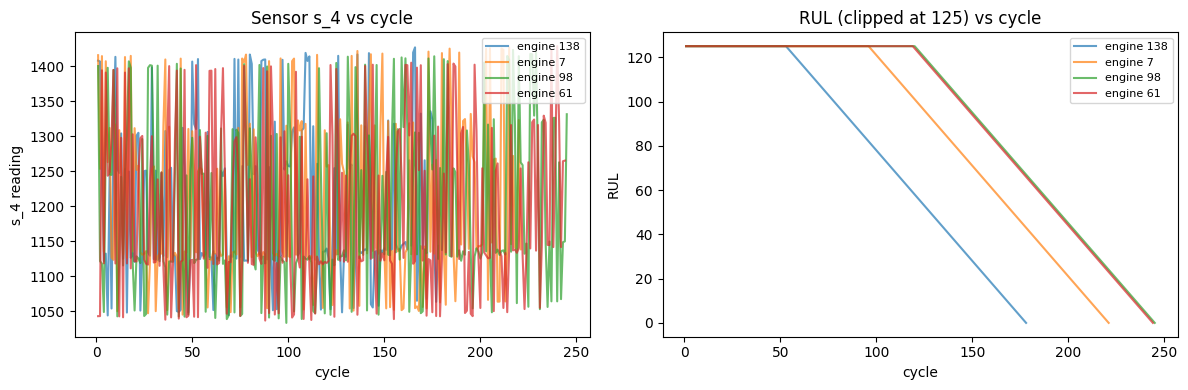

In [6]:
sample_engines = train['unit_number'].drop_duplicates().sample(4, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for eng in sample_engines:
    sub = train[train['unit_number'] == eng]
    axes[0].plot(sub['time_cycles'], sub['s_4'], alpha=0.7, label=f'engine {eng}')
    axes[1].plot(sub['time_cycles'], sub['RUL'], alpha=0.7, label=f'engine {eng}')

axes[0].set_title('Sensor s_4 vs cycle')
axes[0].set_xlabel('cycle'); axes[0].set_ylabel('s_4 reading')
axes[1].set_title('RUL (clipped at 125) vs cycle')
axes[1].set_xlabel('cycle'); axes[1].set_ylabel('RUL')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('/mnt/user-data/outputs/eda_sensor_rul_trajectories.png', dpi=120)
plt.show()

## 7. Why we must split by engine, not by row

If we randomly split *rows* into train/validation, consecutive cycles from the *same engine* end up on both sides. The model then partially memorizes that engine's specific trajectory instead of learning generalizable degradation patterns — this is leakage, and it will make validation scores look better than real-world performance.

The correct approach: hold out entire engines.

In [7]:
from sklearn.model_selection import train_test_split

all_units = train['unit_number'].unique()
train_units, val_units = train_test_split(all_units, test_size=0.2, random_state=42)

train_split = train[train['unit_number'].isin(train_units)]
val_split   = train[train['unit_number'].isin(val_units)]

print(f'Train engines: {len(train_units)} ({train_split.shape[0]} rows)')
print(f'Val engines:   {len(val_units)} ({val_split.shape[0]} rows)')

Train engines: 199 (49294 rows)
Val engines:   50 (11955 rows)


## 8. Save a clean, labeled version for the next notebook

Next notebook (`02_baseline_umap_kmeans_lad.ipynb`) starts from here: scaling, operating-condition normalization, then UMAP → K-Means → LAD → FTA.

In [8]:
import os
os.makedirs('/home/claude/project/data', exist_ok=True)
train.to_csv('/home/claude/project/data/train_FD004_labeled.csv', index=False)
test.to_csv('/home/claude/project/data/test_FD004_raw.csv', index=False)
print('Saved.')

Saved.
